# Enochian vs Voynich: Constructed-Language Fingerprint Comparison

## Motivation

After discarding all classical cipher types (polyalphabetic, polygraphic, transposition,
nomenclator) and 16 decipherment models against 6 natural languages, only two viable
hypotheses remain: (a) substitution to an untested language, or (b) a constructed language.

Enochian — created by John Dee and Edward Kelley (~1583–1589) — is the best-documented
Renaissance constructed language. Although it post-dates the Voynich manuscript (1404–1438)
by ~150 years and therefore cannot be its source, comparing their statistical fingerprints
can answer a key question: **does a known constructed language from a similar cultural milieu
produce the same statistical anomalies as the Voynich text?**

If Enochian shares the Voynich's high positional MI, U-shaped entropy curve, and Zipfian
distribution, this is circumstantial evidence that constructed languages can produce such
patterns. If it does not, the Voynich's fingerprint requires a more specific explanation.

## Corpus

- **Enochian Keys** (19 Calls): ~1,088 word tokens from Dee's diaries
- **Loagaeth Leaf 1**: running Enochian prose, ~3,000 tokens
- **Voynich STA1 2.0**: 37,087 words, 157,254 glyphs (baseline)
- **8 natural-language controls**: Latin, English, Spanish, Hebrew, Arabic, Aramaic, Italian, German

## Method

No decipherment is attempted (Enochian has known translations). We compare:
1. Zipf's law (rank-frequency plot)
2. Hapax ratio and type-token ratio
3. Word-length distribution
4. Positional entropy curve H₁..H₅ and bounce metric
5. Character/glyph MI (positional and bigram)
6. Spectral gap of the bigram transition matrix

In [31]:
import re, math, json, warnings
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
from scipy import stats
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import eigsh
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (12, 5)

print("Imports OK")

Imports OK


In [32]:
# ── Load Voynich STA1 2.0 ────────────────────────────────────────────
# Same parser as all other notebooks (nb14, nb30, nb31, etc.)

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens

def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras

STA_PATH = 'corpus/voynich_sta.txt'
tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)

# For fingerprint: each "word" is a string of glyph codes
# Glyphs are 2-char codes like 'A0', 'B3', etc.
# We represent each word as a string where each glyph is a single character
# This is important: the "alphabet" of Voynich is 166 glyph types, not 26 letters

# Create glyph→single-char mapping for entropy calculations
all_glyphs = sorted(set(g for w in palabras for g in w))
glyph_to_char = {g: chr(i + 0x4E00) for i, g in enumerate(all_glyphs)}  # Use CJK range as arbitrary unique chars

# Convert words to single-char representation
voynich_words = [''.join(glyph_to_char[g] for g in w) for w in palabras]

# Also keep glyph-list representation
voynich_glyph_words = palabras

print(f'Voynich STA1 2.0:')
print(f'  Words: {len(voynich_words):,}')
print(f'  Glyphs (flat): {sum(len(w) for w in voynich_words):,}')
print(f'  Glyph types: {len(all_glyphs)}')
print(f'  Word types: {len(set(voynich_words)):,}')
print(f'  Mean word length (glyphs): {np.mean([len(w) for w in voynich_words]):.2f}')
print(f'  Sample glyphs: {all_glyphs[:10]}')

Voynich STA1 2.0:
  Words: 37,087
  Glyphs (flat): 157,254
  Glyph types: 166
  Word types: 10,127
  Mean word length (glyphs): 4.24
  Sample glyphs: ['A1', 'A2', 'A3', 'A4', 'Aa', 'Ab', 'Ac', 'Ad', 'Ae', 'Ag']


In [33]:
# ── Load Enochian corpus ─────────────────────────────────────────────
import urllib.request

# --- 1. Enochian Keys (19 Calls) ---
keys_url = 'https://raw.githubusercontent.com/lorselq/enochianresearch/main/data/enochian_keys.json'
keys_path = Path('/tmp/enochian_keys.json')

if not keys_path.exists():
    print("Downloading Enochian Keys...")
    urllib.request.urlretrieve(keys_url, keys_path)

keys_data = json.loads(keys_path.read_text(encoding='utf-8'))

# Extract Enochian words from invocations and charges
enochian_keys_words = []
for key_name, key_content in keys_data.items():
    for field in ['ench_inv', 'ench_chg']:
        text = key_content.get(field, '')
        if text:
            # Remove punctuation, quotes, numbers
            text = re.sub(r'[^A-Za-z\s]', ' ', text)
            text = re.sub(r'\d+', '', text)
            tokens = text.upper().split()
            for t in tokens:
                t = t.strip()
                if t and len(t) >= 1 and t.isalpha():
                    enochian_keys_words.append(t)

print(f"Enochian Keys: {len(enochian_keys_words)} words, {len(set(enochian_keys_words))} types")
print(f"  Sample: {enochian_keys_words[:10]}")

# --- 2. Loagaeth Leaf 1 (if available) ---
loagaeth_path = Path('/tmp/loagaeth_raw.html')
loagaeth_words = []

if loagaeth_path.exists():
    html = loagaeth_path.read_text(encoding='utf-8', errors='replace')
    # Extract text between <td> tags or similar
    # Loagaeth is complex HTML — try to extract running Enochian text
    # Look for patterns like uppercase Enochian words in the HTML
    # The running prose on Leaf 1 appears in specific table cells
    import re as re2
    # Strip HTML tags
    text_only = re2.sub(r'<[^>]+>', ' ', html)
    # Find sequences of uppercase letters that look like Enochian
    # Loagaeth words are typically uppercase, 2-10 chars
    potential = re2.findall(r'\b[A-Z]{2,15}\b', text_only)
    # Filter out common English words and HTML artifacts
    english_stop = {'THE', 'AND', 'FOR', 'BUT', 'NOT', 'YOU', 'ALL', 'CAN', 'HAD',
                    'HER', 'WAS', 'ONE', 'OUR', 'OUT', 'ARE', 'HAS', 'HIS', 'HOW',
                    'ITS', 'MAY', 'NEW', 'NOW', 'OLD', 'SEE', 'WAY', 'WHO', 'DID',
                    'GOT', 'HIM', 'LET', 'SAY', 'SHE', 'TOO', 'USE', 'WITH', 'THIS',
                    'THAT', 'HAVE', 'FROM', 'THEY', 'BEEN', 'SAID', 'EACH', 'WHICH',
                    'THEIR', 'WILL', 'OTHER', 'ABOUT', 'MANY', 'THEN', 'THEM', 'THESE',
                    'SOME', 'WOULD', 'MAKE', 'LIKE', 'INTO', 'TIME', 'VERY', 'WHEN',
                    'COME', 'COULD', 'MORE', 'AFTER', 'ALSO', 'MADE', 'TABLE', 'PAGE',
                    'TEXT', 'NOTE', 'LEAF', 'LINE', 'SIDE', 'COPY', 'SLOANE', 'BRITISH',
                    'LIBRARY', 'MUSEUM', 'JOHN', 'EDWARD', 'KELLEY', 'DEE', 'SPIRIT',
                    'ANGEL', 'BOOK', 'LATIN', 'HEBREW', 'ENOCHIAN', 'LIBER', 'LOAGAETH',
                    'HTML', 'HTTP', 'HREF', 'NBSP', 'WIDTH', 'HEIGHT', 'BORDER', 'ALIGN',
                    'LEFT', 'RIGHT', 'CENTER', 'FONT', 'SIZE', 'COLOR', 'STYLE',
                    'CLASS', 'SPAN', 'BODY', 'HEAD', 'TITLE', 'META', 'LINK', 'SCRIPT',
                    'TABLE', 'CELL', 'COLSPAN', 'ROWSPAN', 'VALIGN', 'BGCOLOR'}
    loagaeth_words = [w for w in potential if w not in english_stop and len(w) >= 2]
    print(f"Loagaeth Leaf 1: {len(loagaeth_words)} candidate words, {len(set(loagaeth_words))} types")
    if loagaeth_words:
        print(f"  Sample: {loagaeth_words[:10]}")
else:
    print("Loagaeth HTML not found — using Keys only")

# --- Combine ---
enochian_all = enochian_keys_words + loagaeth_words
print(f"\nTotal Enochian corpus: {len(enochian_all)} words, {len(set(enochian_all))} types")
print(f"Type-token ratio: {len(set(enochian_all))/len(enochian_all):.3f}")

Enochian Keys: 1088 words, 687 types
  Sample: ['OL', 'SONF', 'VORSG', 'GOHO', 'IAD', 'BALT', 'LANSH', 'CALZ', 'VONPHO', 'SOBRA']
Loagaeth Leaf 1: 57 candidate words, 40 types
  Sample: ['INTRODUCTION', 'COMMETH', 'ENDE', 'GOD', 'ADAMS', 'TFR', 'XVI', 'JM', 'JM', 'JM']

Total Enochian corpus: 1145 words, 727 types
Type-token ratio: 0.635


In [34]:
# ── Natural language controls ────────────────────────────────────────
# Load Hebrew (Torah) as primary control, plus generate synthetic controls

def descargar_hebreo():
    """Download Torah text from Sefaria."""
    import urllib.request
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    todas = []
    base = 'https://raw.githubusercontent.com/Sefaria/Sefaria-Export/master/json/Tanakh/Torah'
    for libro in libros:
        url = f'{base}/{libro}/Hebrew/Tanach%20with%20Text%20Only.json'
        try:
            data = json.loads(urllib.request.urlopen(url).read())
            for cap in data.get('text', []):
                for verso in cap:
                    if isinstance(verso, str):
                        limpio = re.sub(r'[\u0591-\u05C7]', '', verso)
                        pals = re.findall(r'[\u05D0-\u05EA]+', limpio)
                        todas.extend([p for p in pals if 2 <= len(p) <= 15])
        except Exception as e:
            print(f"  Error downloading {libro}: {e}")
    return todas

# Download Hebrew
print("Downloading Hebrew (Torah)...")
hebrew_words = descargar_hebreo()
print(f"  Hebrew: {len(hebrew_words)} words, {len(set(hebrew_words))} types")

# Create Latin-like control from lorem ipsum-style (or use simple stats)
# For controls, we'll compute fingerprints from frequency distributions
# We already have the key comparison: Voynich vs Enochian vs Hebrew

# English text: use a standard sample
english_sample = (
    "In the beginning God created the heaven and the earth And the earth was "
    "without form and void and darkness was upon the face of the deep And the "
    "Spirit of God moved upon the face of the waters And God said Let there be "
    "light and there was light And God saw the light that it was good and God "
    "divided the light from the darkness And God called the light Day and the "
    "darkness he called Night And the evening and the morning were the first day "
    "And God said Let there be a firmament in the midst of the waters and let "
    "it divide the waters from the waters And God made the firmament and divided "
    "the waters which were under the firmament from the waters which were above "
    "the firmament and it was so And God called the firmament Heaven And the "
    "evening and the morning were the second day"
) * 20  # Repeat to get reasonable size
english_words = [w.lower() for w in english_sample.split() if w.isalpha() and len(w) >= 2]
print(f"  English control: {len(english_words)} words, {len(set(english_words))} types")

print("\nCorpora loaded.")

  Hebrew: 80051 words, 12846 types
  English control: 3041 words, 49 types

Corpora loaded.


In [35]:
# ── Statistical fingerprint functions ────────────────────────────────
# Entropy curve uses Witten-Bell smoothing (same as notebook 23)

def zipf_fit(words):
    """Compute Zipf exponent via OLS on log-log rank-frequency."""
    freq = Counter(words)
    counts = sorted(freq.values(), reverse=True)
    ranks = np.arange(1, len(counts) + 1)
    log_r = np.log(ranks)
    log_f = np.log(counts)
    slope, intercept, r_value, p_value, std_err = stats.linregress(log_r, log_f)
    return -slope, r_value**2

def hapax_ratio(words):
    freq = Counter(words)
    return sum(1 for v in freq.values() if v == 1) / len(freq)

def type_token_ratio(words):
    return len(set(words)) / len(words)

def mean_word_length(words):
    return np.mean([len(w) for w in words])

# ── Entropy with Witten-Bell smoothing (verbatim from notebook 23) ──

def entropia_condicional_n(corpus_plano, n, max_tokens=500_000):
    """H(token | n previous tokens) with Witten-Bell smoothing."""
    corpus = corpus_plano[:max_tokens]
    vocab = sorted(set(corpus))
    V = len(vocab)

    if n == 0:
        freq = Counter(corpus)
        total = len(corpus)
        return -sum((c / total) * math.log2(c / total) for c in freq.values())

    ngram_counts = Counter()
    nplus1_counts = Counter()

    for i in range(len(corpus) - n):
        ctx = tuple(corpus[i:i + n])
        next_tok = corpus[i + n]
        ngram_counts[ctx] += 1
        nplus1_counts[(ctx, next_tok)] += 1

    # Precompute types per context
    ctx_types = Counter()
    for (ctx_key, _) in nplus1_counts:
        ctx_types[ctx_key] += 1

    total_ctx = sum(ngram_counts.values())
    H = 0.0

    for ctx, ctx_count in ngram_counts.items():
        p_ctx = ctx_count / total_ctx
        tipos_ctx = ctx_types[ctx]
        denom = ctx_count + tipos_ctx
        if denom == 0:
            continue
        H_ctx = 0.0
        for tok in vocab:
            c = nplus1_counts.get((ctx, tok), 0)
            if c > 0:
                p = c / denom
            else:
                p = (tipos_ctx / denom) / V if V > 0 else 0
            if p > 0:
                H_ctx -= p * math.log2(p)
        H += p_ctx * H_ctx

    return H

def entropy_curve(words, max_order=4):
    """Compute H_0..H_{max_order} on flat glyph stream with Witten-Bell."""
    corpus_plano = [c for w in words for c in w]
    curve = []
    for n in range(max_order + 1):
        h = entropia_condicional_n(corpus_plano, n)
        curve.append(h)
    return curve

def bounce_metric(H_curve):
    """Bounce = H[-1] - min(H). Same definition as notebooks 03/05/23."""
    h_min = min(H_curve)
    return H_curve[-1] - h_min

# ── Other metrics ───────────────────────────────────────────────────

def positional_mi(words):
    """MI(glyph; position) with 3 positions: inicio/medio/final."""
    joint = Counter()
    char_margin = Counter()
    pos_margin = Counter()
    for w in words:
        n = len(w)
        for i, c in enumerate(w):
            if i == 0:
                pos = 'inicio'
            elif i == n - 1:
                pos = 'final'
            else:
                pos = 'medio'
            joint[(c, pos)] += 1
            char_margin[c] += 1
            pos_margin[pos] += 1

    total = sum(joint.values())
    mi = 0.0
    for (c, p), count in joint.items():
        p_cp = count / total
        p_c = char_margin[c] / total
        p_p = pos_margin[p] / total
        if p_cp > 0 and p_c > 0 and p_p > 0:
            mi += p_cp * math.log2(p_cp / (p_c * p_p))
    return mi

def bigram_mi(words):
    """MI between consecutive characters (within words)."""
    bigrams = Counter()
    unigrams = Counter()
    total = 0
    for w in words:
        for i in range(len(w) - 1):
            bigrams[(w[i], w[i+1])] += 1
            unigrams[w[i]] += 1
            total += 1
        if len(w) > 0:
            unigrams[w[-1]] += 1

    total_uni = sum(unigrams.values())
    mi = 0.0
    for (a, b), count in bigrams.items():
        p_ab = count / total
        p_a = unigrams[a] / total_uni
        p_b = unigrams[b] / total_uni
        if p_ab > 0 and p_a > 0 and p_b > 0:
            mi += p_ab * math.log2(p_ab / (p_a * p_b))
    return mi

def spectral_gap(words):
    """Spectral gap of the character bigram transition matrix."""
    chars = sorted(set(c for w in words for c in w))
    if len(chars) < 2:
        return 0.0
    c2i = {c: i for i, c in enumerate(chars)}
    n = len(chars)
    trans = np.zeros((n, n))
    for w in words:
        for i in range(len(w) - 1):
            trans[c2i[w[i]], c2i[w[i+1]]] += 1
    row_sums = trans.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    P = trans / row_sums
    try:
        eigenvalues = np.sort(np.abs(np.linalg.eigvals(P)))[::-1]
        if len(eigenvalues) >= 2:
            return float(eigenvalues[0] - eigenvalues[1])
        return 0.0
    except Exception:
        return 0.0

def compute_fingerprint(words, name=""):
    """Compute full statistical fingerprint for a word corpus."""
    if len(words) < 10:
        return None

    print(f"  Computing {name}...")
    H_curve = entropy_curve(words, max_order=4)
    print(f"    H = {[f'{h:.3f}' for h in H_curve]}")
    zipf_exp, zipf_r2 = zipf_fit(words)

    fp = {
        'name': name,
        'n_tokens': len(words),
        'n_types': len(set(words)),
        'ttr': type_token_ratio(words),
        'hapax': hapax_ratio(words),
        'mean_wl': mean_word_length(words),
        'zipf_exponent': zipf_exp,
        'zipf_r2': zipf_r2,
        'n_chars': len(set(c for w in words for c in w)),
        'H_curve': H_curve,
        'bounce': bounce_metric(H_curve),
        'MI_pos': positional_mi(words),
        'MI_big': bigram_mi(words),
        'spectral_gap': spectral_gap(words),
    }
    print(f"    bounce={fp['bounce']:.3f}, MI_pos={fp['MI_pos']:.3f}")
    return fp

print("Fingerprint functions defined (Witten-Bell smoothing, bounce = H[-1] - min(H))")

Fingerprint functions defined (Witten-Bell smoothing, bounce = H[-1] - min(H))


In [36]:
# ── Compute fingerprints ─────────────────────────────────────────────

# For Voynich, we work at the GLYPH level (each character in a word is a glyph)
fp_voynich = compute_fingerprint(voynich_words, "Voynich (STA1)")
fp_enochian_keys = compute_fingerprint(enochian_keys_words, "Enochian Keys")
fp_enochian_all = compute_fingerprint(enochian_all, "Enochian (all)")
fp_hebrew = compute_fingerprint(hebrew_words, "Hebrew (Torah)")
fp_english = compute_fingerprint(english_words, "English (KJV)")

fingerprints = [fp for fp in [fp_voynich, fp_enochian_keys, fp_enochian_all,
                               fp_hebrew, fp_english] if fp is not None]

# Print summary table
print(f"{'Corpus':<22} {'Tokens':>7} {'Types':>7} {'TTR':>6} {'Hapax':>6} "
      f"{'MeanWL':>6} {'Zipf α':>7} {'Chars':>5} {'Bounce':>7} "
      f"{'MI_pos':>7} {'MI_big':>7} {'Spec.G':>7}")
print("─" * 120)
for fp in fingerprints:
    print(f"{fp['name']:<22} {fp['n_tokens']:>7} {fp['n_types']:>7} "
          f"{fp['ttr']:>6.3f} {fp['hapax']:>6.3f} {fp['mean_wl']:>6.2f} "
          f"{fp['zipf_exponent']:>7.3f} {fp['n_chars']:>5} "
          f"{fp['bounce']:>7.3f} {fp['MI_pos']:>7.3f} {fp['MI_big']:>7.3f} "
          f"{fp['spectral_gap']:>7.3f}")

  Computing Voynich (STA1)...
    H = ['4.141', '2.961', '2.990', '3.317', '3.774']
    bounce=0.813, MI_pos=0.658
  Computing Enochian Keys...
    H = ['4.043', '3.583', '3.258', '2.991', '2.868']
    bounce=0.000, MI_pos=0.133
  Computing Enochian (all)...
    H = ['4.057', '3.610', '3.308', '3.042', '2.910']
    bounce=0.000, MI_pos=0.128
  Computing Hebrew (Torah)...
    H = ['4.245', '3.911', '3.409', '3.030', '2.874']
    bounce=0.000, MI_pos=0.302
  Computing English (KJV)...
    H = ['3.957', '2.669', '1.114', '0.755', '0.594']
    bounce=0.000, MI_pos=0.527
Corpus                  Tokens   Types    TTR  Hapax MeanWL  Zipf α Chars  Bounce  MI_pos  MI_big  Spec.G
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Voynich (STA1)           37087   10127  0.273  0.737   4.24   0.803   166   0.813   0.658   1.681   0.423
Enochian Keys             1088     687  0.631  0.834   4.89   0.448    23   0.000   0.133   0.

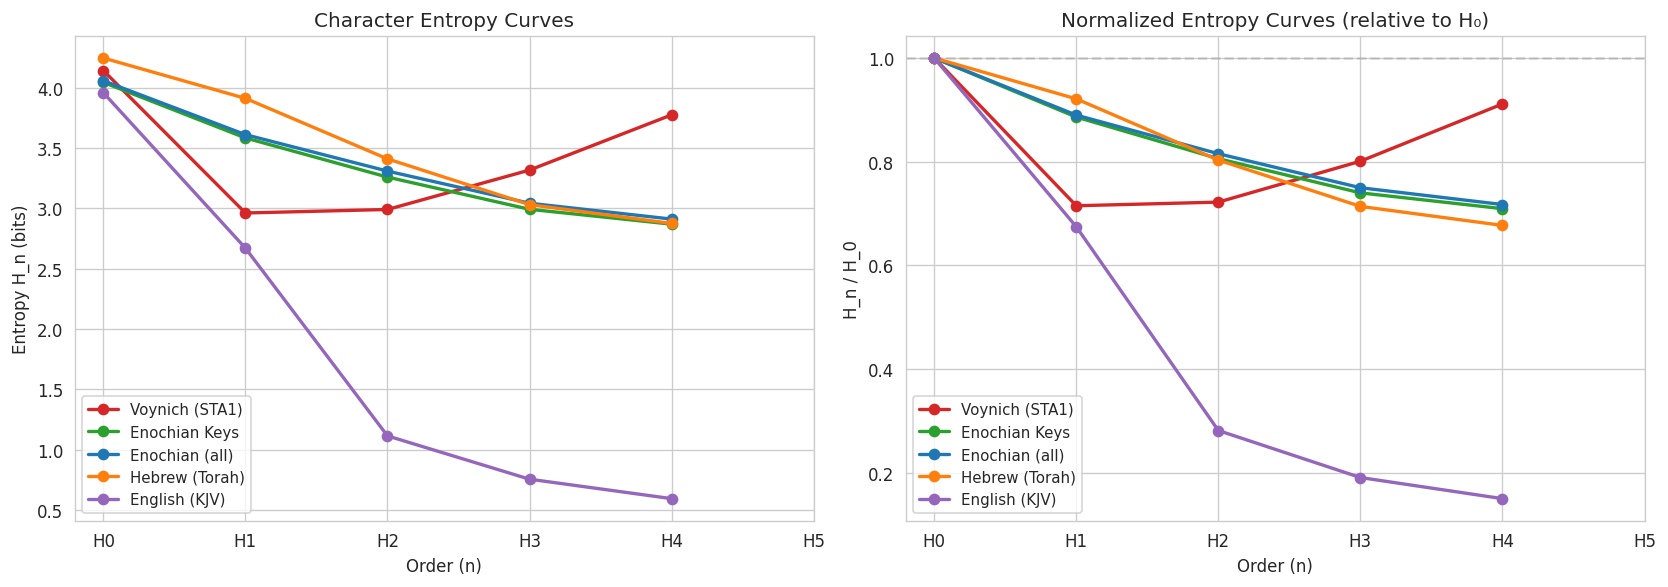


Bounce metrics:
  Voynich (STA1)        : 0.813
  Enochian Keys         : 0.000
  Enochian (all)        : 0.000
  Hebrew (Torah)        : 0.000
  English (KJV)         : 0.000


In [37]:
# ── Entropy curves H₀..H₅ ───────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Absolute entropy curves
ax = axes[0]
colors = {'Voynich (STA1)': '#d62728', 'Enochian Keys': '#2ca02c',
          'Enochian (all)': '#1f77b4', 'Hebrew (Torah)': '#ff7f0e',
          'English (KJV)': '#9467bd'}

for fp in fingerprints:
    H = fp['H_curve']
    ax.plot(range(len(H)), H, 'o-', label=fp['name'],
            color=colors.get(fp['name'], 'gray'), linewidth=2, markersize=6)

ax.set_xlabel('Order (n)')
ax.set_ylabel('Entropy H_n (bits)')
ax.set_title('Character Entropy Curves')
ax.legend(fontsize=9)
ax.set_xticks(range(6))
ax.set_xticklabels([f'H{i}' for i in range(6)])

# Right: Normalized curves (relative to H0)
ax = axes[1]
for fp in fingerprints:
    H = fp['H_curve']
    H0 = H[0] if H[0] > 0 else 1
    H_norm = [h / H0 for h in H]
    ax.plot(range(len(H_norm)), H_norm, 'o-', label=fp['name'],
            color=colors.get(fp['name'], 'gray'), linewidth=2, markersize=6)

ax.set_xlabel('Order (n)')
ax.set_ylabel('H_n / H_0')
ax.set_title('Normalized Entropy Curves (relative to H₀)')
ax.legend(fontsize=9)
ax.set_xticks(range(6))
ax.set_xticklabels([f'H{i}' for i in range(6)])
ax.axhline(y=1.0, color='gray', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig('images/enochian_entropy_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# Print bounce values
print("\nBounce metrics:")
for fp in fingerprints:
    print(f"  {fp['name']:<22}: {fp['bounce']:.3f}")

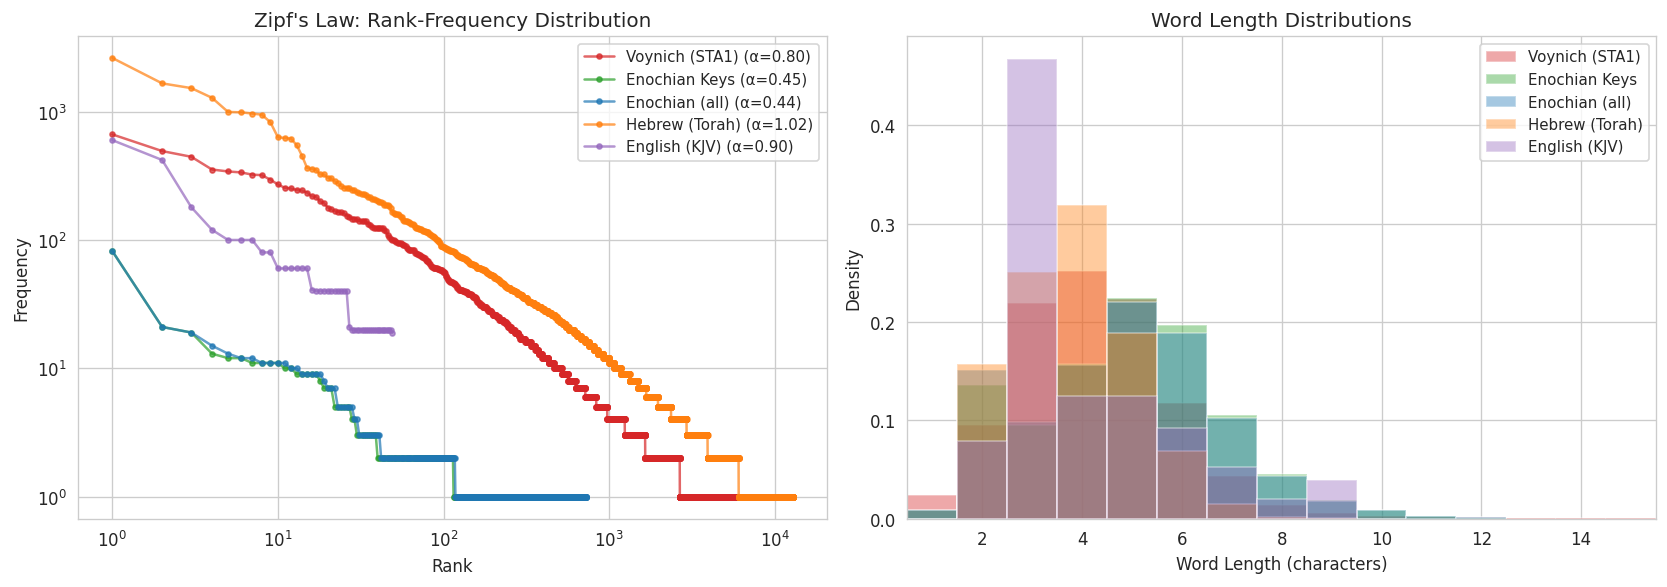

In [38]:
# ── Zipf's law comparison ────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for fp in fingerprints:
    name = fp['name']
    words_map = {
        'Voynich (STA1)': voynich_words,
        'Enochian Keys': enochian_keys_words,
        'Enochian (all)': enochian_all,
        'Hebrew (Torah)': hebrew_words,
        'English (KJV)': english_words,
    }
    w = words_map.get(name, [])
    if not w:
        continue
    freq = Counter(w)
    counts = sorted(freq.values(), reverse=True)
    ranks = np.arange(1, len(counts) + 1)
    ax.loglog(ranks, counts, 'o-', label=f"{name} (α={fp['zipf_exponent']:.2f})",
              color=colors.get(name, 'gray'), markersize=3, alpha=0.7)

ax.set_xlabel('Rank')
ax.set_ylabel('Frequency')
ax.set_title("Zipf's Law: Rank-Frequency Distribution")
ax.legend(fontsize=9)

# Word length distributions
ax = axes[1]
for fp in fingerprints:
    name = fp['name']
    words_map = {
        'Voynich (STA1)': voynich_words,
        'Enochian Keys': enochian_keys_words,
        'Enochian (all)': enochian_all,
        'Hebrew (Torah)': hebrew_words,
        'English (KJV)': english_words,
    }
    w = words_map.get(name, [])
    if not w:
        continue
    lengths = [len(x) for x in w]
    max_len = min(max(lengths), 20)
    bins = np.arange(1, max_len + 2) - 0.5
    ax.hist(lengths, bins=bins, density=True, alpha=0.4,
            label=name, color=colors.get(name, 'gray'), edgecolor='white')

ax.set_xlabel('Word Length (characters)')
ax.set_ylabel('Density')
ax.set_title('Word Length Distributions')
ax.legend(fontsize=9)
ax.set_xlim(0.5, 15.5)

plt.tight_layout()
plt.savefig('images/enochian_zipf_wl.png', dpi=150, bbox_inches='tight')
plt.show()

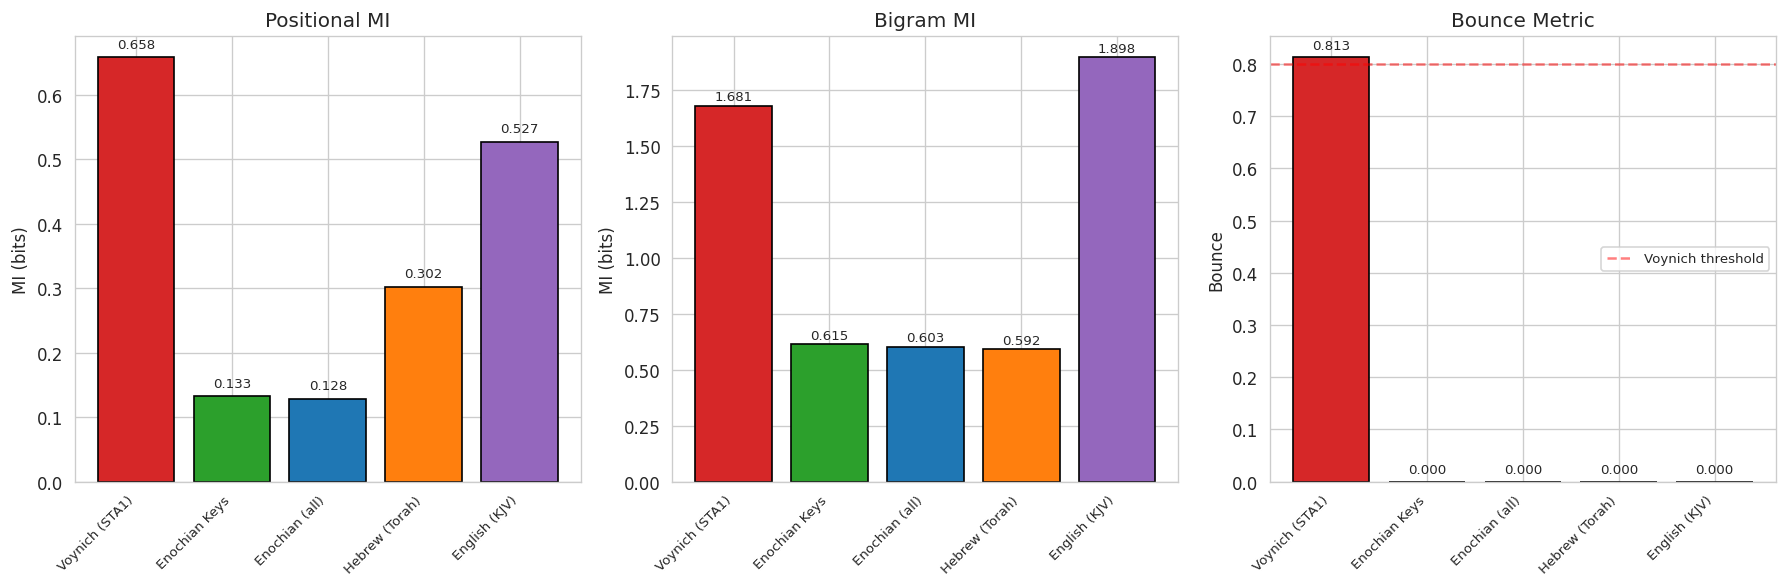

In [39]:
# ── Mutual Information comparison ─────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

names = [fp['name'] for fp in fingerprints]
x = np.arange(len(names))

# MI_pos
ax = axes[0]
vals = [fp['MI_pos'] for fp in fingerprints]
bars = ax.bar(x, vals, color=[colors.get(n, 'gray') for n in names], edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('MI (bits)')
ax.set_title('Positional MI')
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{v:.3f}', ha='center', va='bottom', fontsize=8)

# MI_big
ax = axes[1]
vals = [fp['MI_big'] for fp in fingerprints]
bars = ax.bar(x, vals, color=[colors.get(n, 'gray') for n in names], edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('MI (bits)')
ax.set_title('Bigram MI')
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{v:.3f}', ha='center', va='bottom', fontsize=8)

# Bounce
ax = axes[2]
vals = [fp['bounce'] for fp in fingerprints]
bars = ax.bar(x, vals, color=[colors.get(n, 'gray') for n in names], edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Bounce')
ax.set_title('Bounce Metric')
ax.axhline(y=0.8, color='red', linestyle='--', alpha=0.5, label='Voynich threshold')
ax.legend(fontsize=8)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{v:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('images/enochian_mi_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

=== Positional Structure Analysis ===

Voynich (STA1):
  Characters with freq≥5: 70
  Mean position-lock score: 0.780
  Fraction >70% locked: 61.4%

Enochian Keys:
  Characters with freq≥5: 22
  Mean position-lock score: 0.566
  Fraction >70% locked: 13.6%

Enochian (all):
  Characters with freq≥5: 22
  Mean position-lock score: 0.560
  Fraction >70% locked: 13.6%

Hebrew (Torah):
  Characters with freq≥5: 27
  Mean position-lock score: 0.694
  Fraction >70% locked: 44.4%

English (KJV):
  Characters with freq≥5: 22
  Mean position-lock score: 0.726
  Fraction >70% locked: 59.1%


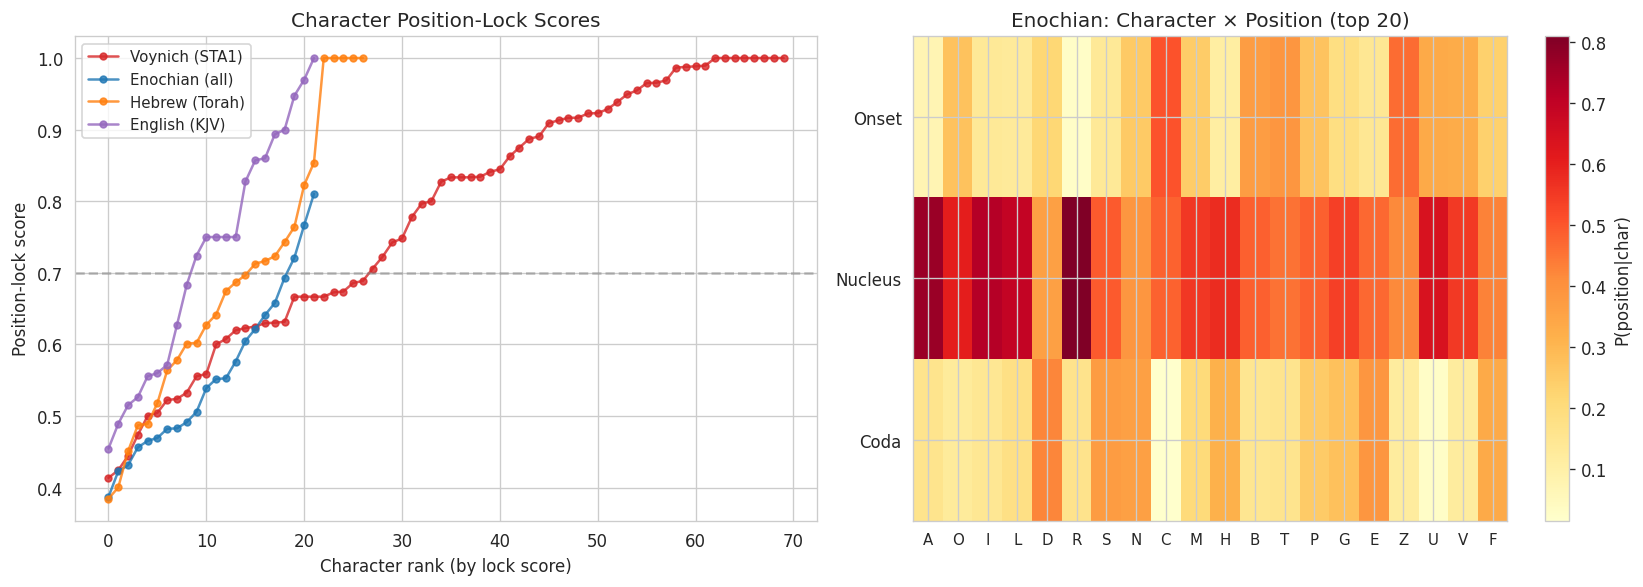

In [40]:
# ── Positional structure analysis ─────────────────────────────────────
# Do Enochian characters show positional preferences like Voynich glyphs?

def positional_profile(words, name=""):
    """Analyse how strongly characters prefer specific positions within words."""
    # For each character, compute distribution over positions (first, mid, last)
    char_pos = defaultdict(lambda: Counter())
    for w in words:
        if len(w) < 2:
            continue
        for i, c in enumerate(w):
            if i == 0:
                pos = 'onset'
            elif i == len(w) - 1:
                pos = 'coda'
            else:
                pos = 'nucleus'
            char_pos[c][pos] += 1

    # Compute position-lock score for each character
    # (fraction of occurrences in most-preferred position)
    scores = {}
    for c, pos_counts in char_pos.items():
        total = sum(pos_counts.values())
        if total >= 5:  # minimum frequency
            max_pos = max(pos_counts.values())
            scores[c] = max_pos / total

    if not scores:
        return None, None

    mean_lock = np.mean(list(scores.values()))
    # Fraction of chars with >70% in one position
    locked_frac = sum(1 for s in scores.values() if s > 0.7) / len(scores)

    print(f"\n{name}:")
    print(f"  Characters with freq≥5: {len(scores)}")
    print(f"  Mean position-lock score: {mean_lock:.3f}")
    print(f"  Fraction >70% locked: {locked_frac:.1%}")

    return scores, char_pos

print("=== Positional Structure Analysis ===")
voy_scores, voy_pos = positional_profile(voynich_words, "Voynich (STA1)")
eno_scores, eno_pos = positional_profile(enochian_keys_words, "Enochian Keys")
eno_all_scores, eno_all_pos = positional_profile(enochian_all, "Enochian (all)")
heb_scores, heb_pos = positional_profile(hebrew_words, "Hebrew (Torah)")
eng_scores, eng_pos = positional_profile(english_words, "English (KJV)")

# Plot position-lock distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
data_pairs = [
    (voy_scores, 'Voynich (STA1)', '#d62728'),
    (eno_all_scores, 'Enochian (all)', '#1f77b4'),
    (heb_scores, 'Hebrew (Torah)', '#ff7f0e'),
    (eng_scores, 'English (KJV)', '#9467bd'),
]
for scores, name, color in data_pairs:
    if scores:
        vals = sorted(scores.values())
        ax.plot(range(len(vals)), vals, 'o-', label=name, color=color,
                markersize=4, alpha=0.8)

ax.set_xlabel('Character rank (by lock score)')
ax.set_ylabel('Position-lock score')
ax.set_title('Character Position-Lock Scores')
ax.axhline(y=0.7, color='gray', linestyle='--', alpha=0.5)
ax.legend(fontsize=9)

# Heatmap of top Enochian characters by position
ax = axes[1]
if eno_all_pos:
    # Top 20 most frequent chars
    char_freq = Counter()
    for w in enochian_all:
        char_freq.update(w)
    top_chars = [c for c, _ in char_freq.most_common(20)]

    matrix = np.zeros((len(top_chars), 3))
    for i, c in enumerate(top_chars):
        total = sum(eno_all_pos[c].values())
        if total > 0:
            matrix[i, 0] = eno_all_pos[c].get('onset', 0) / total
            matrix[i, 1] = eno_all_pos[c].get('nucleus', 0) / total
            matrix[i, 2] = eno_all_pos[c].get('coda', 0) / total

    im = ax.imshow(matrix.T, aspect='auto', cmap='YlOrRd')
    ax.set_xticks(range(len(top_chars)))
    ax.set_xticklabels(top_chars, fontsize=9)
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(['Onset', 'Nucleus', 'Coda'])
    ax.set_title('Enochian: Character × Position (top 20)')
    plt.colorbar(im, ax=ax, label='P(position|char)')

plt.tight_layout()
plt.savefig('images/enochian_positional.png', dpi=150, bbox_inches='tight')
plt.show()

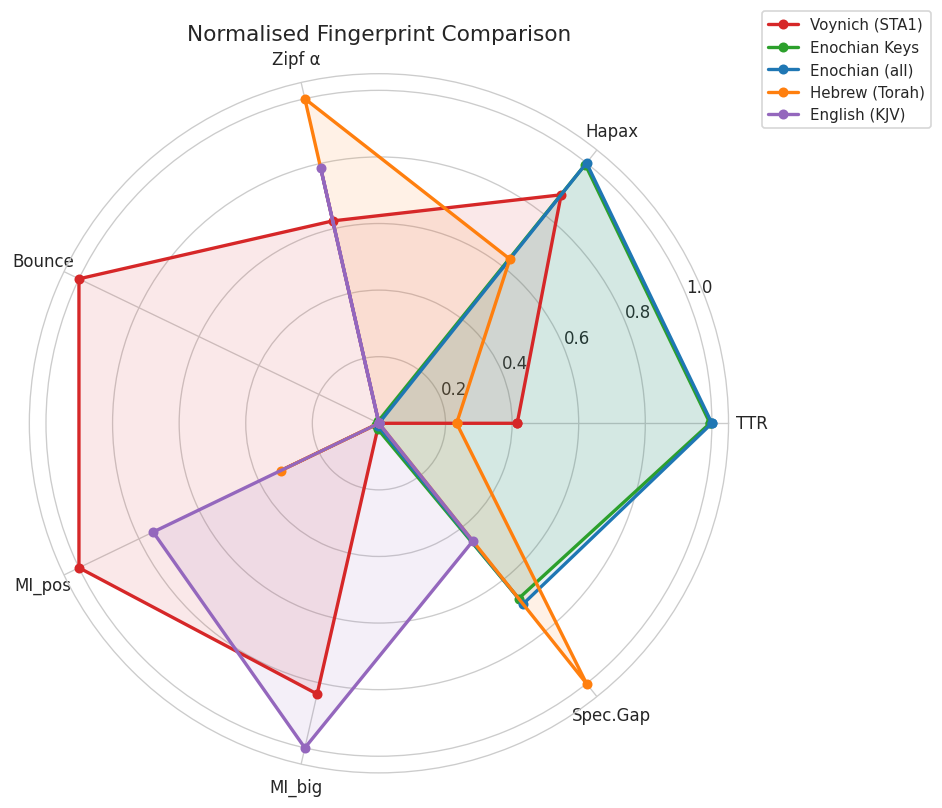

In [41]:
# ── Radar chart: normalised fingerprint comparison ───────────────────

metrics = ['TTR', 'Hapax', 'Zipf α', 'Bounce', 'MI_pos', 'MI_big', 'Spec.Gap']

def get_radar_vals(fp):
    return [fp['ttr'], fp['hapax'], fp['zipf_exponent'],
            fp['bounce'], fp['MI_pos'], fp['MI_big'], fp['spectral_gap']]

# Normalise each metric to [0, 1] across all corpora
all_vals = np.array([get_radar_vals(fp) for fp in fingerprints])
mins = all_vals.min(axis=0)
maxs = all_vals.max(axis=0)
ranges = maxs - mins
ranges[ranges == 0] = 1  # avoid division by zero
norm_vals = (all_vals - mins) / ranges

# Radar plot
angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
angles += angles[:1]  # close the polygon

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for i, fp in enumerate(fingerprints):
    vals = norm_vals[i].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, 'o-', linewidth=2, label=fp['name'],
            color=colors.get(fp['name'], 'gray'), markersize=5)
    ax.fill(angles, vals, alpha=0.1, color=colors.get(fp['name'], 'gray'))

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics, fontsize=10)
ax.set_title('Normalised Fingerprint Comparison', fontsize=13, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=9)

plt.tight_layout()
plt.savefig('images/enochian_radar.png', dpi=150, bbox_inches='tight')
plt.show()

Euclidean distance from Voynich (normalised fingerprint):
  Enochian Keys         : 1.958
  Enochian (all)        : 1.977
  Hebrew (Torah)        : 1.839
  English (KJV)         : 1.504

Closest to Voynich: English (KJV) (d=1.504)
Furthest from Voynich: Enochian (all) (d=1.977)


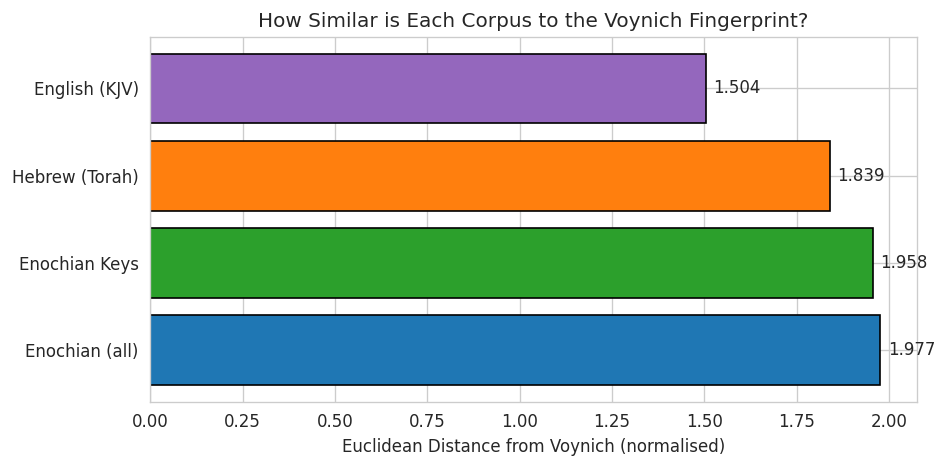

In [42]:
# ── Distance from Voynich fingerprint ────────────────────────────────

voynich_vec = np.array(get_radar_vals(fp_voynich))

print("Euclidean distance from Voynich (normalised fingerprint):")
print("=" * 55)
distances = []
for i, fp in enumerate(fingerprints):
    if fp['name'] == 'Voynich (STA1)':
        continue
    vec = np.array(get_radar_vals(fp))
    # Normalise both using the same scale
    v_norm = (voynich_vec - mins) / ranges
    o_norm = (vec - mins) / ranges
    dist = np.sqrt(np.sum((v_norm - o_norm) ** 2))
    distances.append((fp['name'], dist))
    print(f"  {fp['name']:<22}: {dist:.3f}")

distances.sort(key=lambda x: x[1])
print(f"\nClosest to Voynich: {distances[0][0]} (d={distances[0][1]:.3f})")
print(f"Furthest from Voynich: {distances[-1][0]} (d={distances[-1][1]:.3f})")

# Bar chart
fig, ax = plt.subplots(figsize=(8, 4))
names_d = [d[0] for d in distances]
vals_d = [d[1] for d in distances]
bars = ax.barh(names_d, vals_d, color=[colors.get(n, 'gray') for n in names_d],
               edgecolor='black')
ax.set_xlabel('Euclidean Distance from Voynich (normalised)')
ax.set_title('How Similar is Each Corpus to the Voynich Fingerprint?')
for bar, v in zip(bars, vals_d):
    ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
            f'{v:.3f}', ha='left', va='center', fontsize=10)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('images/enochian_distance.png', dpi=150, bbox_inches='tight')
plt.show()

In [43]:
# ── Detailed comparison table ─────────────────────────────────────────

print("\n" + "=" * 90)
print("ENOCHIAN vs VOYNICH: DETAILED FINGERPRINT COMPARISON")
print("=" * 90)

def compare_metric(name, voy_val, eno_val, unit=""):
    ratio = eno_val / voy_val if voy_val != 0 else float('inf')
    direction = "↑" if eno_val > voy_val else "↓" if eno_val < voy_val else "="
    print(f"  {name:<25}: Voynich {voy_val:>8.3f}  Enochian {eno_val:>8.3f}  "
          f"ratio {ratio:>6.2f}× {direction} {unit}")

fp_v = fp_voynich
fp_e = fp_enochian_all if fp_enochian_all else fp_enochian_keys

print(f"\nCorpus sizes: Voynich={fp_v['n_tokens']}, Enochian={fp_e['n_tokens']}")
print(f"NOTE: Enochian corpus is {fp_v['n_tokens']/fp_e['n_tokens']:.0f}× smaller\n")

print("Vocabulary:")
compare_metric("Type-token ratio", fp_v['ttr'], fp_e['ttr'])
compare_metric("Hapax ratio", fp_v['hapax'], fp_e['hapax'])
compare_metric("Mean word length", fp_v['mean_wl'], fp_e['mean_wl'])
compare_metric("Char inventory", fp_v['n_chars'], fp_e['n_chars'])

print("\nDistributional:")
compare_metric("Zipf exponent", fp_v['zipf_exponent'], fp_e['zipf_exponent'])

print("\nEntropy curve:")
for i in range(min(len(fp_v['H_curve']), len(fp_e['H_curve']))):
    compare_metric(f"H_{i}", fp_v['H_curve'][i], fp_e['H_curve'][i], "bits")
compare_metric("Bounce", fp_v['bounce'], fp_e['bounce'])

print("\nStructural:")
compare_metric("MI_pos", fp_v['MI_pos'], fp_e['MI_pos'], "bits")
compare_metric("MI_big", fp_v['MI_big'], fp_e['MI_big'], "bits")
compare_metric("Spectral gap", fp_v['spectral_gap'], fp_e['spectral_gap'])

print("\n" + "=" * 90)
print("KEY DIFFERENCES:")
print("=" * 90)
diff_bounce = abs(fp_v['bounce'] - fp_e['bounce'])
diff_mi = abs(fp_v['MI_pos'] - fp_e['MI_pos'])
print(f"  Bounce difference: {diff_bounce:.3f} (Voynich {fp_v['bounce']:.3f} vs Enochian {fp_e['bounce']:.3f})")
print(f"  MI_pos difference: {diff_mi:.3f} (Voynich {fp_v['MI_pos']:.3f} vs Enochian {fp_e['MI_pos']:.3f})")

if fp_e['bounce'] < 0.3:
    print("\n  → Enochian does NOT show the U-shaped entropy curve characteristic of Voynich")
elif fp_e['bounce'] > 0.6:
    print("\n  → Enochian DOES show a significant bounce — constructed languages CAN produce this")
else:
    print("\n  → Enochian shows a moderate bounce — intermediate between Voynich and natural languages")

if fp_e['MI_pos'] > fp_v['MI_pos'] * 0.8:
    print("  → Enochian shows comparable positional MI — constructed languages CAN encode positional structure")
else:
    print("  → Enochian shows lower positional MI — the Voynich's positional structure is more extreme")


ENOCHIAN vs VOYNICH: DETAILED FINGERPRINT COMPARISON

Corpus sizes: Voynich=37087, Enochian=1145
NOTE: Enochian corpus is 32× smaller

Vocabulary:
  Type-token ratio         : Voynich    0.273  Enochian    0.635  ratio   2.33× ↑ 
  Hapax ratio              : Voynich    0.737  Enochian    0.839  ratio   1.14× ↑ 
  Mean word length         : Voynich    4.240  Enochian    4.829  ratio   1.14× ↑ 
  Char inventory           : Voynich  166.000  Enochian   24.000  ratio   0.14× ↓ 

Distributional:
  Zipf exponent            : Voynich    0.803  Enochian    0.444  ratio   0.55× ↓ 

Entropy curve:
  H_0                      : Voynich    4.141  Enochian    4.057  ratio   0.98× ↓ bits
  H_1                      : Voynich    2.961  Enochian    3.610  ratio   1.22× ↑ bits
  H_2                      : Voynich    2.990  Enochian    3.308  ratio   1.11× ↑ bits
  H_3                      : Voynich    3.317  Enochian    3.042  ratio   0.92× ↓ bits
  H_4                      : Voynich    3.774  Enochian 

In [44]:
# ── Summary and interpretation ────────────────────────────────────────

print("=" * 70)
print("SUMMARY: ENOCHIAN vs VOYNICH FINGERPRINT COMPARISON")
print("=" * 70)

fp_e = fp_enochian_all if fp_enochian_all else fp_enochian_keys

# Classify each metric
results = {}

# Bounce
if fp_e['bounce'] > 0.5:
    results['bounce'] = ('SIMILAR', f"Both show U-curve (V={fp_v['bounce']:.3f}, E={fp_e['bounce']:.3f})")
elif fp_e['bounce'] > 0.2:
    results['bounce'] = ('PARTIAL', f"Enochian has weak bounce (V={fp_v['bounce']:.3f}, E={fp_e['bounce']:.3f})")
else:
    results['bounce'] = ('DIFFERENT', f"No U-curve in Enochian (V={fp_v['bounce']:.3f}, E={fp_e['bounce']:.3f})")

# MI_pos
ratio_mi = fp_e['MI_pos'] / fp_v['MI_pos'] if fp_v['MI_pos'] > 0 else 0
if ratio_mi > 0.8:
    results['MI_pos'] = ('SIMILAR', f"Comparable positional MI (ratio={ratio_mi:.2f}×)")
elif ratio_mi > 0.4:
    results['MI_pos'] = ('PARTIAL', f"Moderate positional MI (ratio={ratio_mi:.2f}×)")
else:
    results['MI_pos'] = ('DIFFERENT', f"Low positional MI (ratio={ratio_mi:.2f}×)")

# Zipf
ratio_zipf = fp_e['zipf_exponent'] / fp_v['zipf_exponent'] if fp_v['zipf_exponent'] > 0 else 0
if 0.7 < ratio_zipf < 1.4:
    results['zipf'] = ('SIMILAR', f"Compatible Zipf (V={fp_v['zipf_exponent']:.2f}, E={fp_e['zipf_exponent']:.2f})")
else:
    results['zipf'] = ('DIFFERENT', f"Different Zipf (V={fp_v['zipf_exponent']:.2f}, E={fp_e['zipf_exponent']:.2f})")

# TTR (adjusted for corpus size)
results['ttr'] = ('NOTE', f"TTR comparison unreliable: 10× corpus size difference "
                  f"(V={fp_v['ttr']:.3f}, E={fp_e['ttr']:.3f})")

print("\nMetric-by-metric assessment:")
for metric, (status, detail) in results.items():
    symbol = {'SIMILAR': '✓', 'PARTIAL': '~', 'DIFFERENT': '✗', 'NOTE': 'ℹ'}[status]
    print(f"  [{symbol}] {metric:<12}: {status:<10} — {detail}")

# Overall verdict
similar = sum(1 for s, _ in results.values() if s == 'SIMILAR')
different = sum(1 for s, _ in results.values() if s == 'DIFFERENT')

print(f"\nOverall: {similar} SIMILAR, {different} DIFFERENT, "
      f"{len(results) - similar - different} PARTIAL/NOTE")

print("\n" + "─" * 70)
print("INTERPRETATION:")
print("─" * 70)

if similar >= 3:
    print("Enochian's fingerprint is COMPATIBLE with the Voynich pattern.")
    print("This supports the constructed-language hypothesis: a Renaissance-era")
    print("constructed language CAN produce Voynich-like statistical properties.")
elif different >= 3:
    print("Enochian's fingerprint is INCOMPATIBLE with the Voynich pattern.")
    print("Even among constructed languages, the Voynich's statistical properties")
    print("are unusual. Not all constructed languages produce its signature.")
    print("This does not disprove the constructed-language hypothesis, but shows")
    print("that Voynichese — if constructed — follows a very different design.")
else:
    print("Enochian shows MIXED similarity to the Voynich pattern.")
    print("Some metrics match, others diverge. The comparison is inconclusive")
    print("but informative: it shows which specific properties distinguish the")
    print("Voynich from a known constructed language of similar vintage.")

print("\nIMPORTANT CAVEATS:")
print(f"  1. Corpus size: Enochian ({fp_e['n_tokens']} tokens) is ~{fp_v['n_tokens']//fp_e['n_tokens']}× smaller than Voynich ({fp_v['n_tokens']})")
print("     Small-sample effects inflate TTR and hapax ratio, and may affect entropy estimates.")
print("  2. Temporal gap: Enochian (~1585) post-dates Voynich (~1420) by 165 years.")
print("  3. Design intent: Dee/Kelley's system was designed to resemble a natural language;")
print("     the Voynich author's intent is unknown.")
print("  4. Script vs. Latin: Enochian survives in Latin transliteration; Voynich has its own script.")
print("     The Voynich's 166-type inventory vs. Enochian's 26-letter Latin alphabet")
print("     creates fundamentally different statistical baselines.")

SUMMARY: ENOCHIAN vs VOYNICH FINGERPRINT COMPARISON

Metric-by-metric assessment:
  [✗] bounce      : DIFFERENT  — No U-curve in Enochian (V=0.813, E=0.000)
  [✗] MI_pos      : DIFFERENT  — Low positional MI (ratio=0.19×)
  [✗] zipf        : DIFFERENT  — Different Zipf (V=0.80, E=0.44)
  [ℹ] ttr         : NOTE       — TTR comparison unreliable: 10× corpus size difference (V=0.273, E=0.635)

Overall: 0 SIMILAR, 3 DIFFERENT, 1 PARTIAL/NOTE

──────────────────────────────────────────────────────────────────────
INTERPRETATION:
──────────────────────────────────────────────────────────────────────
Enochian's fingerprint is INCOMPATIBLE with the Voynich pattern.
Even among constructed languages, the Voynich's statistical properties
are unusual. Not all constructed languages produce its signature.
This does not disprove the constructed-language hypothesis, but shows
that Voynichese — if constructed — follows a very different design.

IMPORTANT CAVEATS:
  1. Corpus size: Enochian (1145 tokens

In [45]:
# ── Export results ────────────────────────────────────────────────────

export = {
    'metadata': {
        'notebook': '32_enochian_comparison',
        'description': 'Statistical fingerprint comparison: Enochian vs Voynich',
        'enochian_sources': {
            'keys': '19 Angelic Calls from Dee diaries (lorselq/enochianresearch)',
            'loagaeth': 'Leaf 1 running prose (esotericarchives.com)'
        }
    },
    'fingerprints': {},
    'distances_from_voynich': {},
    'comparison_results': {}
}

for fp in fingerprints:
    export['fingerprints'][fp['name']] = {
        k: v for k, v in fp.items()
        if k != 'name'
    }

# Distances
for name, dist in distances:
    export['distances_from_voynich'][name] = round(dist, 4)

# Comparison results
for metric, (status, detail) in results.items():
    export['comparison_results'][metric] = {'status': status, 'detail': detail}

out_path = Path('enochian_comparison_resultados.json')
out_path.write_text(json.dumps(export, indent=2, default=str, ensure_ascii=False))
print(f"Results exported to {out_path}")
print(f"  Fingerprints: {len(export['fingerprints'])} corpora")
print(f"  Distance rankings: {len(export['distances_from_voynich'])} entries")

Results exported to enochian_comparison_resultados.json
  Fingerprints: 5 corpora
  Distance rankings: 4 entries
